In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#those are seperate cause  those are other than KNN
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [4]:
df = pd.read_csv('/content/heart_cleveland_upload (1).csv')

In [5]:
X = df.drop(columns=['condition'])
y = df['condition']

In [6]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ])

In [9]:
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
    ])

In [10]:
knn_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp',
                                                   'trestbps', 'chol', 'fbs',
                                                   'restecg', 'thalach',
                                                   'exang', 'oldpeak', 'slope',
                                                   'ca', 'thal']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  [])])),
                ('classifier', KNeighborsClassifier())])

In [11]:
y_pred = knn_pipeline.predict(X_test)

In [12]:
print("accuracy")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred)*100:.4f}%")

accuracy
Accuracy Score: 90.0000%


In [13]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        32
           1       1.00      0.79      0.88        28

    accuracy                           0.90        60
   macro avg       0.92      0.89      0.90        60
weighted avg       0.92      0.90      0.90        60

Confusion Matrix:
[[32  0]
 [ 6 22]]


In [14]:
k_values = range(1, 50)
accuracies = []

for k in k_values:

    # Create pipeline with different K
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])


    model.fit(X_train, y_train)


    y_pred_k = model.predict(X_test)


    acc = accuracy_score(y_test, y_pred_k)
    accuracies.append(acc)

    print(f"K = {k} ---> Accuracy = {acc*100:.2f}%")

K = 1 ---> Accuracy = 78.33%
K = 2 ---> Accuracy = 76.67%
K = 3 ---> Accuracy = 86.67%
K = 4 ---> Accuracy = 86.67%
K = 5 ---> Accuracy = 90.00%
K = 6 ---> Accuracy = 83.33%
K = 7 ---> Accuracy = 88.33%
K = 8 ---> Accuracy = 83.33%
K = 9 ---> Accuracy = 88.33%
K = 10 ---> Accuracy = 86.67%
K = 11 ---> Accuracy = 90.00%
K = 12 ---> Accuracy = 83.33%
K = 13 ---> Accuracy = 86.67%
K = 14 ---> Accuracy = 85.00%
K = 15 ---> Accuracy = 86.67%
K = 16 ---> Accuracy = 85.00%
K = 17 ---> Accuracy = 88.33%
K = 18 ---> Accuracy = 86.67%
K = 19 ---> Accuracy = 86.67%
K = 20 ---> Accuracy = 86.67%
K = 21 ---> Accuracy = 88.33%
K = 22 ---> Accuracy = 86.67%
K = 23 ---> Accuracy = 86.67%
K = 24 ---> Accuracy = 86.67%
K = 25 ---> Accuracy = 88.33%
K = 26 ---> Accuracy = 86.67%
K = 27 ---> Accuracy = 86.67%
K = 28 ---> Accuracy = 86.67%
K = 29 ---> Accuracy = 86.67%
K = 30 ---> Accuracy = 86.67%
K = 31 ---> Accuracy = 86.67%
K = 32 ---> Accuracy = 86.67%
K = 33 ---> Accuracy = 86.67%
K = 34 ---> Accurac

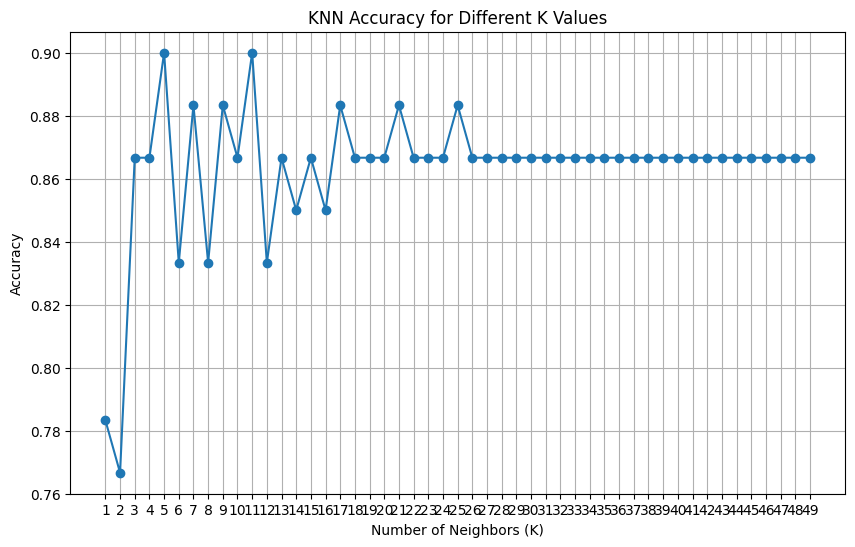

In [15]:
plt.figure(figsize=(10,6))

plt.plot(k_values, accuracies, marker='o')

plt.title('KNN Accuracy for Different K Values')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')

plt.xticks(k_values)

plt.grid(True)

plt.show()

In [16]:
best_k = k_values[accuracies.index(max(accuracies))]
best_accuracy = max(accuracies)

print(f"Best K Value: {best_k}")
print(f"Best Accuracy: {best_accuracy*100:.2f}%")

Best K Value: 5
Best Accuracy: 90.00%


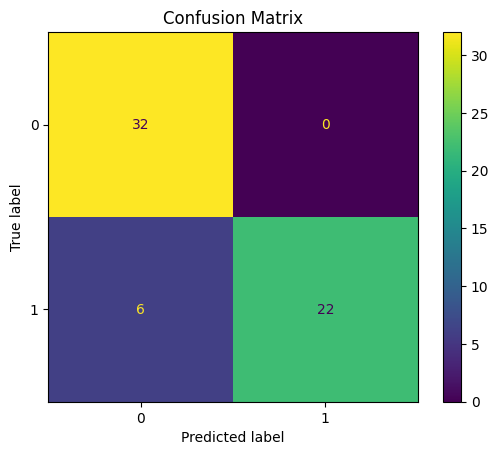

In [17]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [18]:
models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Logistic Regression": LogisticRegression()
}

for name, model in models.items():

    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipe.fit(X_train, y_train)

    score = pipe.score(X_test, y_test)

    print(f"{name}: {score*100:.2f}%")

KNN: 90.00%
Decision Tree: 78.33%
Random Forest: 86.67%
Logistic Regression: 91.67%


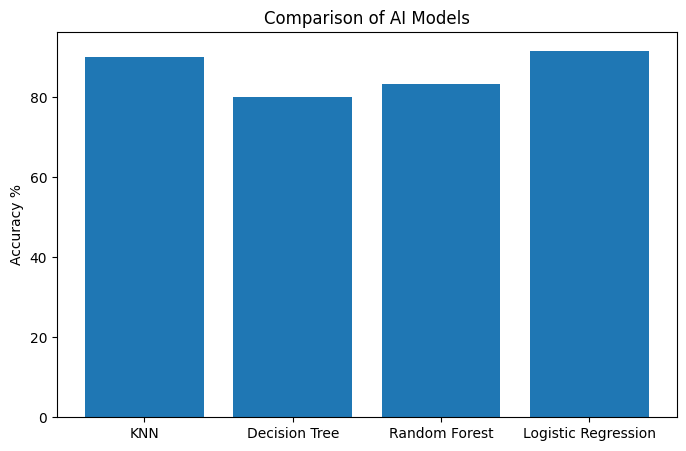

In [19]:
model_names = []
model_scores = []

for name, model in models.items():

    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipe.fit(X_train, y_train)

    score = pipe.score(X_test, y_test)

    model_names.append(name)
    model_scores.append(score*100)

plt.figure(figsize=(8,5))

plt.bar(model_names, model_scores)

plt.ylabel("Accuracy %")
plt.title("Comparison of AI Models")

plt.show()

In [20]:

sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Prediction:", prediction)

Prediction: [0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [21]:
sample = pd.DataFrame([[
    52,    # age
    1,     # sex
    2,     # cp
    130,   # trestbps
    250,   # chol
    0,     # fbs
    1,     # restecg
    170,   # thalach
    0,     # exang
    1.2,   # oldpeak
    2,     # slope
    0,     # ca
    2      # thal
]], columns=X.columns)

In [22]:
trained_models = {}
for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe

for name, model in trained_models.items():

    prediction = model.predict(sample)

    if prediction[0] == 1:
        result = "Heart Disease Detected"
    else:
        result = "No Heart Disease"

    print(f"{name}: {result}")

KNN: No Heart Disease
Decision Tree: No Heart Disease
Random Forest: No Heart Disease
Logistic Regression: Heart Disease Detected
